<a href="https://colab.research.google.com/github/Adhityayusuf/mesin-learning/blob/main/JS05/JS05_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()  # pilih voice.csv

df = pd.read_csv('voice.csv')
df.head()

Saving voice.csv to voice (1).csv


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [2]:
print(df.shape)
print('\n')
print(df['label'].value_counts())
print('\n')
print(df.info())
print('\n')
print('Missing value per kolom:')
print(df.isnull().sum())

(3168, 21)


label
male      1584
female    1584
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float

In [3]:
df['label'] = df['label'].map({'male': 1, 'female': 0})

X = df.drop('label', axis=1)
y = df['label']

print(X.columns.tolist())

['meanfreq', 'sd', 'median', 'Q25', 'Q75', 'IQR', 'skew', 'kurt', 'sp.ent', 'sfm', 'mode', 'centroid', 'meanfun', 'minfun', 'maxfun', 'meandom', 'mindom', 'maxdom', 'dfrange', 'modindx']


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(2534, 20) (634, 20)


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

base_model = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

base_model.fit(X_train, y_train)

acc_train = accuracy_score(y_train, base_model.predict(X_train))
acc_test = accuracy_score(y_test, base_model.predict(X_test))

print(f'Akurasi train (semua fitur, k=5): {acc_train:.4f}')
print(f'Akurasi test  (semua fitur, k=5): {acc_test:.4f}')

Akurasi train (semua fitur, k=5): 0.9830
Akurasi test  (semua fitur, k=5): 0.9763


meanfun     5697.873718
IQR         1566.488204
Q25          890.387180
sp.ent       794.113490
sd           750.762545
sfm          375.206538
centroid     324.436358
meanfreq     324.436358
median       218.279695
mindom       100.408598
maxdom        96.538999
dfrange       93.040538
meandom       89.236907
mode          76.078004
maxfun        69.673401
minfun        47.370855
kurt          19.327736
Q75           11.306350
skew           3.812982
modindx        2.112229
dtype: float64


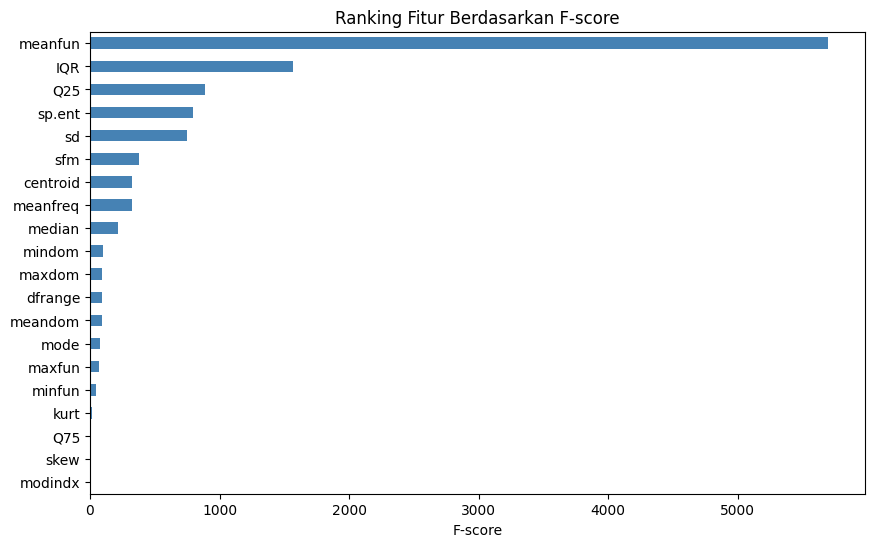

In [6]:
from sklearn.feature_selection import f_classif

f_scores, _ = f_classif(X_train, y_train)
ranking = pd.Series(f_scores, index=X_train.columns).sort_values(ascending=False)

print(ranking)

plt.figure(figsize=(10, 6))
ranking.plot(kind='barh', color='steelblue')
plt.gca().invert_yaxis()
plt.title('Ranking Fitur Berdasarkan F-score')
plt.xlabel('F-score')
plt.show()

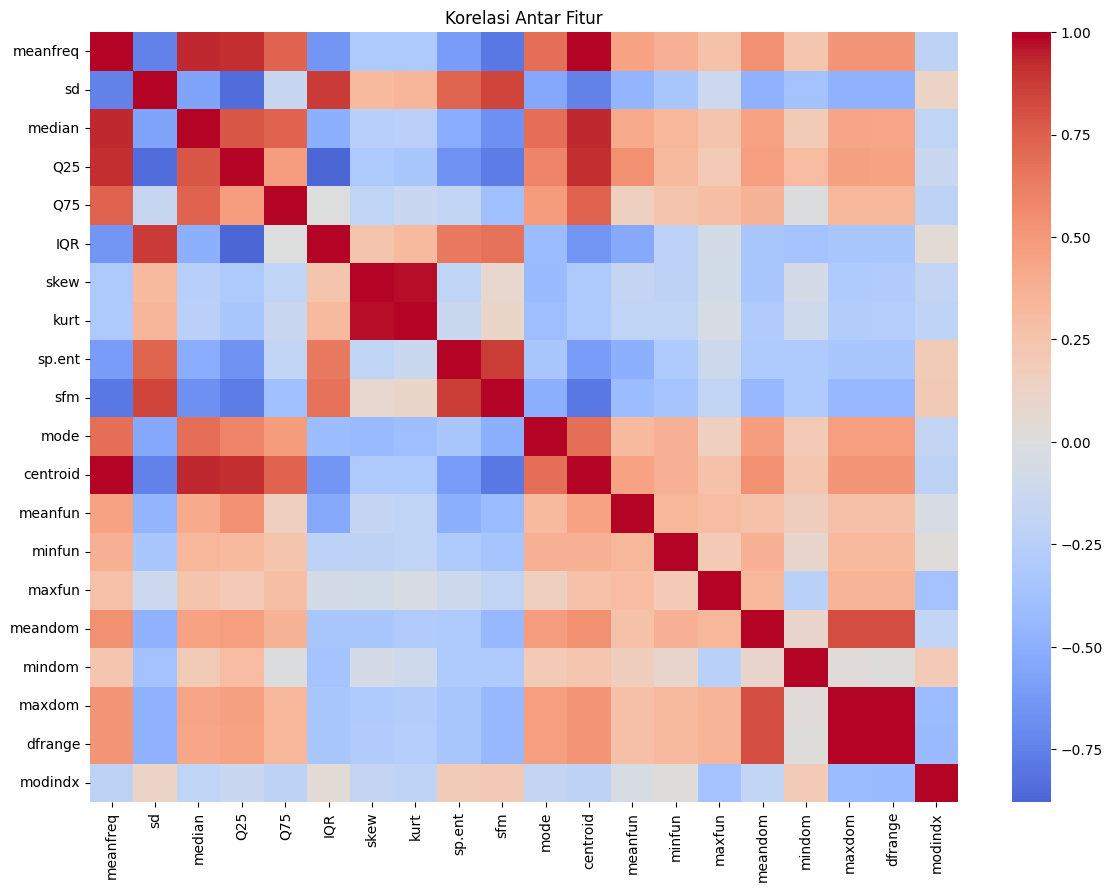

In [7]:
plt.figure(figsize=(14, 10))
sns.heatmap(X_train.corr(), annot=False, cmap='coolwarm', center=0)
plt.title('Korelasi Antar Fitur')
plt.show()

Top- 1 fitur -> akurasi CV: 0.9408
Top- 2 fitur -> akurasi CV: 0.9680
Top- 3 fitur -> akurasi CV: 0.9736
Top- 4 fitur -> akurasi CV: 0.9724
Top- 5 fitur -> akurasi CV: 0.9775
Top- 6 fitur -> akurasi CV: 0.9799
Top- 7 fitur -> akurasi CV: 0.9779
Top- 8 fitur -> akurasi CV: 0.9791
Top- 9 fitur -> akurasi CV: 0.9763
Top-10 fitur -> akurasi CV: 0.9787
Top-11 fitur -> akurasi CV: 0.9759
Top-12 fitur -> akurasi CV: 0.9747
Top-13 fitur -> akurasi CV: 0.9736
Top-14 fitur -> akurasi CV: 0.9708
Top-15 fitur -> akurasi CV: 0.9732
Top-16 fitur -> akurasi CV: 0.9728
Top-17 fitur -> akurasi CV: 0.9720
Top-18 fitur -> akurasi CV: 0.9708
Top-19 fitur -> akurasi CV: 0.9712
Top-20 fitur -> akurasi CV: 0.9696

Jumlah fitur terbaik: 6 (akurasi CV = 0.9799)


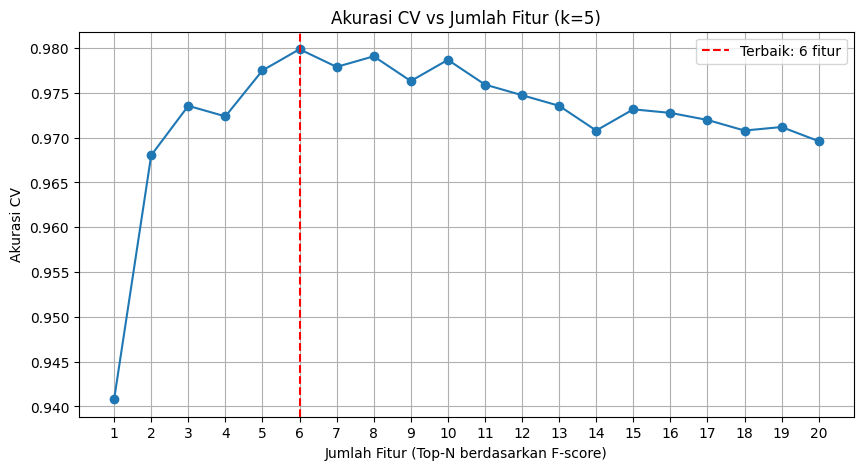

In [8]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.feature_selection import SelectKBest

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

n_features = list(range(1, X_train.shape[1] + 1))
cv_scores = []

for n in n_features:
    pipe = Pipeline([
        ('select', SelectKBest(f_classif, k=n)),
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ])
    score = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='accuracy').mean()
    cv_scores.append(score)
    print(f'Top-{n:2d} fitur -> akurasi CV: {score:.4f}')

best_n = n_features[int(np.argmax(cv_scores))]
print(f'\nJumlah fitur terbaik: {best_n} (akurasi CV = {max(cv_scores):.4f})')

plt.figure(figsize=(10, 5))
plt.plot(n_features, cv_scores, marker='o')
plt.axvline(best_n, color='red', linestyle='--', label=f'Terbaik: {best_n} fitur')
plt.title('Akurasi CV vs Jumlah Fitur (k=5)')
plt.xlabel('Jumlah Fitur (Top-N berdasarkan F-score)')
plt.ylabel('Akurasi CV')
plt.xticks(n_features)
plt.legend()
plt.grid(True)
plt.show()

In [9]:
selector = SelectKBest(f_classif, k=best_n)
selector.fit(X_train, y_train)

selected_features = X_train.columns[selector.get_support()].tolist()
print(f'Fitur yang digunakan ({len(selected_features)}):')
print(selected_features)

X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

Fitur yang digunakan (6):
['sd', 'Q25', 'IQR', 'sp.ent', 'sfm', 'meanfun']


In [10]:
from sklearn.feature_selection import SequentialFeatureSelector

scaler_sfs = StandardScaler().fit(X_train)
X_train_scaled = pd.DataFrame(scaler_sfs.transform(X_train), columns=X_train.columns)

sfs = SequentialFeatureSelector(
    KNeighborsClassifier(n_neighbors=5),
    n_features_to_select='auto',
    tol=0.001,
    direction='forward',
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
sfs.fit(X_train_scaled, y_train)

sfs_features = X_train.columns[sfs.get_support()].tolist()
print(f'Fitur hasil SFS ({len(sfs_features)}): {sfs_features}')

pipe_cmp = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])
acc_sfs = cross_val_score(pipe_cmp, X_train[sfs_features], y_train, cv=skf).mean()
acc_kbest = cross_val_score(pipe_cmp, X_train_sel, y_train, cv=skf).mean()
print(f'Akurasi CV SFS         : {acc_sfs:.4f}')
print(f'Akurasi CV SelectKBest : {acc_kbest:.4f}')

Fitur hasil SFS (6): ['sd', 'median', 'IQR', 'sfm', 'meanfun', 'maxfun']
Akurasi CV SFS         : 0.9787
Akurasi CV SelectKBest : 0.9799


k terbaik: 3 (akurasi CV = 0.9814)


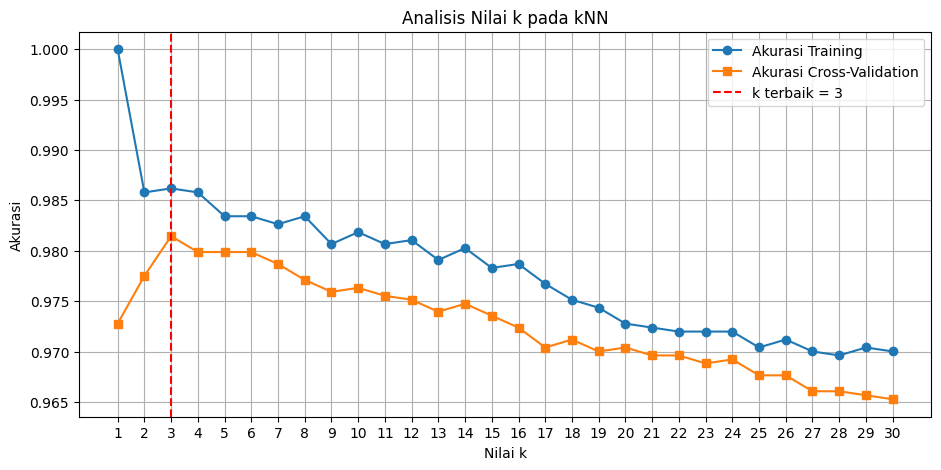

In [11]:
k_range = list(range(1, 31))
cv_acc = []
train_acc = []

def make_pipe(k):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

for k in k_range:
    model = make_pipe(k)
    cv_acc.append(cross_val_score(model, X_train_sel, y_train, cv=skf, scoring='accuracy').mean())
    model.fit(X_train_sel, y_train)
    train_acc.append(accuracy_score(y_train, model.predict(X_train_sel)))

best_k = k_range[int(np.argmax(cv_acc))]
print(f'k terbaik: {best_k} (akurasi CV = {max(cv_acc):.4f})')

plt.figure(figsize=(11, 5))
plt.plot(k_range, train_acc, marker='o', label='Akurasi Training')
plt.plot(k_range, cv_acc, marker='s', label='Akurasi Cross-Validation')
plt.axvline(best_k, color='red', linestyle='--', label=f'k terbaik = {best_k}')
plt.title('Analisis Nilai k pada kNN')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.xticks(k_range)
plt.legend()
plt.grid(True)
plt.show()

Akurasi train: 0.9862
Akurasi test : 0.9874

              precision    recall  f1-score   support

      female       0.99      0.99      0.99       317
        male       0.99      0.99      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



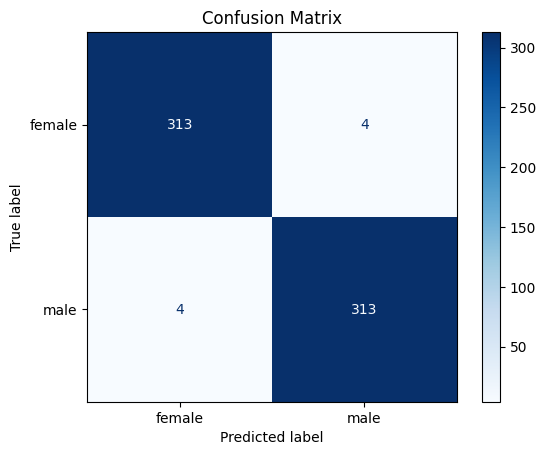

In [12]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

final_model = make_pipe(best_k)
final_model.fit(X_train_sel, y_train)

y_pred = final_model.predict(X_test_sel)

print(f'Akurasi train: {accuracy_score(y_train, final_model.predict(X_train_sel)):.4f}')
print(f'Akurasi test : {accuracy_score(y_test, y_pred):.4f}\n')
print(classification_report(y_test, y_pred, target_names=['female', 'male']))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['female', 'male']).plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

In [13]:
print('=== RINGKASAN HASIL ===')
print(f'Akurasi baseline (semua fitur, k=5) : {accuracy_score(y_test, base_model.predict(X_test)):.4f}')
print(f'Jumlah fitur terbaik                : {best_n}')
print(f'Fitur terpilih                      : {selected_features}')
print(f'Nilai k terbaik                     : {best_k}')
print(f'Akurasi test model akhir            : {accuracy_score(y_test, y_pred):.4f}')

=== RINGKASAN HASIL ===
Akurasi baseline (semua fitur, k=5) : 0.9763
Jumlah fitur terbaik                : 6
Fitur terpilih                      : ['sd', 'Q25', 'IQR', 'sp.ent', 'sfm', 'meanfun']
Nilai k terbaik                     : 3
Akurasi test model akhir            : 0.9874
